# Vectores, sistemas y sensibilidad

## Objetivo
Resolver sistemas, medir residuos y entender por qué una solución puede ser sensible a pequeñas perturbaciones.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Resolver por filas

El sistema $x+y=3$, $2x-y=0$ es $Az=b$. Sumar ecuaciones produce $3x=3$. La solución analítica $(1,2)$ permite comprobar el algoritmo, y el residuo $Az-b$ muestra si satisface las ecuaciones.

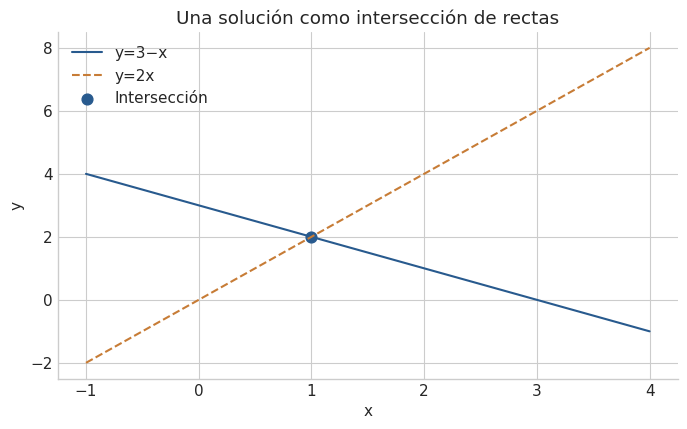

Solución: [1. 2.] ; norma del residuo: 0.0


In [2]:
A=np.array([[1.,1.],[2.,-1.]])
b=np.array([3.,0.])
z=np.linalg.solve(A,b)
print('Solución:',z,'; norma del residuo:',np.linalg.norm(A@z-b))
x=np.linspace(-1,4,100)
fig,ax=plt.subplots()
ax.plot(x,3-x,label='y=3−x'); ax.plot(x,2*x,'--',label='y=2x')
ax.scatter(*z,label='Intersección',s=60)
ax.set(xlabel='x',ylabel='y',title='Una solución como intersección de rectas')
ax.legend(); plt.show()

**Lectura del resultado.** El residuo es cercano a cero. Las rectas se cruzan en (1,2). Un residuo pequeño no garantiza baja sensibilidad frente a errores en los datos.

## 2. Casi la misma ecuación

Usamos $A_\epsilon=\left(\begin{smallmatrix}1&1\\1&1+\epsilon\end{smallmatrix}\right)$ y $b=A_\epsilon(1,1)^T$. Si perturbamos la segunda entrada de $b$ en $\delta$, la segunda incógnita cambia $\delta/\epsilon$ y la primera $-\delta/\epsilon$.

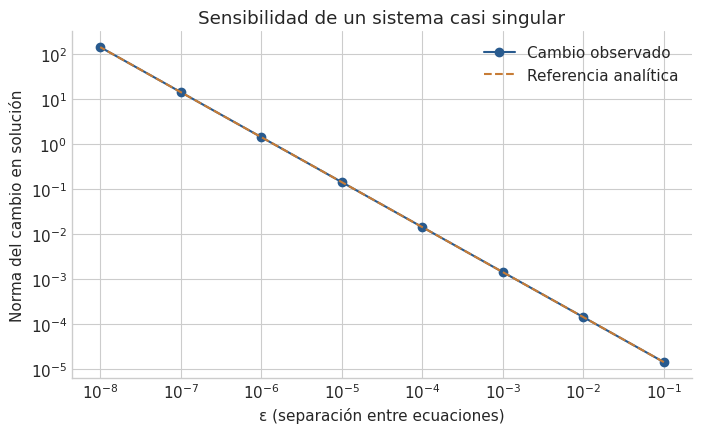

In [3]:
epsilons=np.logspace(-1,-8,8)
errores=[]
for eps in epsilons:
    matriz=np.array([[1.,1.],[1.,1.+eps]])
    rhs=matriz@np.ones(2)
    cambio=np.linalg.solve(matriz,rhs+np.array([0.,1e-6]))-np.ones(2)
    errores.append(np.linalg.norm(cambio))
fig,ax=plt.subplots()
ax.loglog(epsilons,errores,'o-',label='Cambio observado')
ax.loglog(epsilons,np.sqrt(2)*1e-6/epsilons,'--',label='Referencia analítica')
ax.set(xlabel='ε (separación entre ecuaciones)',ylabel='Norma del cambio en solución',title='Sensibilidad de un sistema casi singular')
ax.legend(); plt.show()

**Lectura del resultado.** Al reducir ε, la misma perturbación genera una diferencia mayor. Esto explica por qué columnas casi redundantes complican una estimación.

## Practica antes de ver la solución

Resuelve 2x+y=4, x−y=−1. ¿Qué pasa si duplicas una ecuación y eliminas la otra?

In [4]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

Al sumar: 3x=3, x=1 y y=2. Si solo conservas dos versiones de una ecuación, pierdes una restricción independiente y quedan infinitas soluciones.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [5]:
assert np.allclose(z,[1,2])
assert np.linalg.norm(A@z-b)<1e-12
assert np.allclose(errores,np.sqrt(2)*1e-6/epsilons,rtol=1e-6)
assert np.allclose(np.linalg.solve([[2,1],[1,-1]],[4,-1]),[1,2])
print('Soluciones y sensibilidad: OK')

Soluciones y sensibilidad: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.